# 2 – En Küçük Kareler ve Gauss Eliminasyonu: Panel ısınınca verim ne kadar düşüyor?

Güneş panelleri ısındıkça daha az verimli çalışır. Bu kaybı ölçmek için şu modeli kullanıyoruz:
$$P = a\,G + c\,G\,(T - 25)$$
* $P$: santralin toplam AC gücü (22 inverterin toplamı, kW)
* $G$: güneş ışınımı (kW/m²), $T$: panel sıcaklığı (°C)
* **Sıcaklık katsayısı** $\beta = -c/a$: Panel 25 °C'nin üstünde her 1 °C ısındığında gücün yüzde kaç düştüğü.

Elimizde ≈ 1500 ölçüm (denklem), ama sadece 2 bilinmeyen ($a$, $c$) var. Bu bir **aşırı belirli sistem**: tam çözümü yok,
hataların kareleri toplamını en küçük yapan çözümü arıyoruz.

Kütüphaneleri yüklüyoruz. CSV dosyaları defterle aynı klasörde ya da `../data` klasöründe olabilir.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VERI = Path(".") if Path("Plant_1_Generation_Data.csv").exists() else Path("../data")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Veri

İki dosyanın tarih formatları farklı. Her zaman damgasında 22 inverterin gücünü topluyoruz ve sadece 22 inverterin hepsinin ölçüldüğü anları tutuyoruz
(eksik inverter varsa toplam güç olduğundan küçük görünür). Sonra sensör verisiyle zamana göre birleştirip gece verisini ($G \le 0{,}05$) çıkarıyoruz.

In [2]:
uretim = pd.read_csv(VERI / "Plant_1_Generation_Data.csv")
uretim["DATE_TIME"] = pd.to_datetime(uretim["DATE_TIME"], format="%d-%m-%Y %H:%M")
sensor = pd.read_csv(VERI / "Plant_1_Weather_Sensor_Data.csv")
sensor["DATE_TIME"] = pd.to_datetime(sensor["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")

santral = uretim.groupby("DATE_TIME").agg(P=("AC_POWER", "sum"), n=("AC_POWER", "size")).reset_index()
santral = santral[santral["n"] == 22]
veri = santral.merge(sensor[["DATE_TIME", "IRRADIATION", "MODULE_TEMPERATURE"]], on="DATE_TIME")
veri = veri[veri["IRRADIATION"] > 0.05]

G = veri["IRRADIATION"].to_numpy()
T = veri["MODULE_TEMPERATURE"].to_numpy()
y = veri["P"].to_numpy()
print("Ölçüm (denklem) sayısı:", len(y))
print(f"Panel sıcaklığı: {T.min():.1f} – {T.max():.1f} °C")

Ölçüm (denklem) sayısı: 1508
Panel sıcaklığı: 19.9 – 65.5 °C


## 2. Kısmi pivotlamalı Gauss eliminasyonu

$Ax = b$ sistemini iki aşamada çözer:
1. **İleri eliminasyon:** Her sütunda pivotun altındaki elemanları sıfırlayıp üst üçgen matris elde et. Kısmi pivotlamada her adımda sütundaki **en büyük (mutlak değerce)** elemanı pivot yaparız.
2. **Geri yerine koyma:** Son denklemden başlayarak bilinmeyenleri tek tek bul.

In [3]:
def gauss(A, b, pivot=True):
    """Ax = b'yi Gauss eliminasyonuyla çözer. pivot=True: kısmi pivotlama."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    for k in range(n - 1):
        if pivot:
            p = k + np.argmax(np.abs(A[k:, k]))      # sütundaki en büyük eleman
            A[[k, p]] = A[[p, k]]                    # satırları değiştir
            b[[k, p]] = b[[p, k]]
        for i in range(k + 1, n):
            m = A[i, k] / A[k, k]
            A[i, k:] -= m * A[k, k:]
            b[i] -= m * b[k]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):                   # geri yerine koyma
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

Basit test: Çözümü $x = (1, 2, 3)$ olan 3×3 bir sistemi kendi fonksiyonumuzla ve `np.linalg.solve` ile çözüyoruz.

In [4]:
A3 = np.array([[2.0, 1, -1], [-3, -1, 2], [-2, 1, 2]])
b3 = A3 @ np.array([1.0, 2, 3])
print("Bizim gauss     :", gauss(A3, b3))
print("np.linalg.solve :", np.linalg.solve(A3, b3))

Bizim gauss     : [1. 2. 3.]
np.linalg.solve : [1. 2. 3.]


**Pivotlama neden gerekli?** Aşağıdaki sistemin çözümü yaklaşık $x \approx (1, 1)$'dir.
$$\begin{bmatrix}10^{-17} & 1\\ 1 & 1\end{bmatrix}x = \begin{bmatrix}1\\2\end{bmatrix}$$
Pivotlamasız çözümde ilk adımda $10^{-17}$'ye bölüyoruz; çarpan $10^{17}$ olur ve ikinci denklemdeki bilgi yuvarlama hatasında kaybolur.

In [5]:
A2 = np.array([[1e-17, 1.0], [1.0, 1.0]])
b2 = np.array([1.0, 2.0])
print("Pivotlamalı  :", gauss(A2, b2, pivot=True))
print("Pivotlamasız :", gauss(A2, b2, pivot=False))

Pivotlamalı  : [1. 1.]
Pivotlamasız : [0. 1.]


Pivotlamasız çözümde $x_1 = 0$ çıktı, yani tamamen yanlış. Pivotlamalı çözüm doğru.

## 3. Normal denklemler

$A = [\,G,\ G(T-25)\,]$ matrisini kuruyoruz. $\|Ax - y\|^2$'yi en küçük yapan $x = (a, c)$, türevi sıfıra eşitleyince çıkan
**normal denklemlerin** çözümüdür:
$$A^TA\,x = A^Ty$$
$A^TA$ sadece 2×2 bir matris. Bunu kendi Gauss fonksiyonumuzla çözüp `np.linalg.lstsq` ile karşılaştırıyoruz.

In [6]:
A = np.column_stack([G, G * (T - 25)])
x_bizim = gauss(A.T @ A, A.T @ y)
x_numpy = np.linalg.lstsq(A, y, rcond=None)[0]
print("Bizim (normal denklemler + Gauss):", x_bizim)
print("np.linalg.lstsq                  :", x_numpy)
print(f"κ(A) = {np.linalg.cond(A):.1f},   κ(AᵀA) = {np.linalg.cond(A.T @ A):.0f}")

Bizim (normal denklemler + Gauss): [32405.76767067  -149.68183239]
np.linalg.lstsq                  : [32405.76767067  -149.68183239]
κ(A) = 87.5,   κ(AᵀA) = 7653


İki sonuç aynı. $A^TA$'nın koşul sayısı $A$'nınkinin karesi (87² ≈ 7600). Bu problemde ikisi de küçük, yani normal denklemler güvenle kullanılabilir.

## 4. Sonuç: $a$, $\beta$, $R^2$

$R^2 = 1 - \dfrac{\sum (y - \hat y)^2}{\sum (y - \bar y)^2}$: Güçteki değişimin ne kadarının modelle açıklandığı.

a    = 32406 kW / (kW/m²)
β    = 0.0046 /°C  (her derece için %0.46 güç kaybı)
R²   = 0.983
25 °C → 60 °C güç kaybı: %16.2


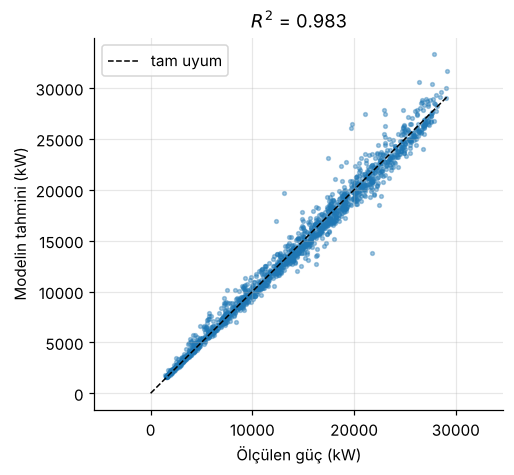

In [7]:
a, c = x_bizim
beta = -c / a
y_tahmin = A @ x_bizim
R2 = 1 - np.sum((y - y_tahmin) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"a    = {a:.0f} kW / (kW/m²)")
print(f"β    = {beta:.4f} /°C  (her derece için %{100 * beta:.2f} güç kaybı)")
print(f"R²   = {R2:.3f}")
print(f"25 °C → 60 °C güç kaybı: %{100 * beta * 35:.1f}")

plt.figure(figsize=(4.8, 4.4))
plt.scatter(y, y_tahmin, s=6, alpha=0.4)
plt.plot([0, y.max()], [0, y.max()], "k--", lw=1, label="tam uyum")
plt.xlabel("Ölçülen güç (kW)"); plt.ylabel("Modelin tahmini (kW)")
plt.title(f"$R^2$ = {R2:.3f}")
plt.legend(); plt.axis("equal"); plt.show()

## Sonuç

* ≈ 1500 ölçümden oluşan aşırı belirli sistemi normal denklemlerle 2×2'ye indirdik ve kendi Gauss eliminasyonumuzla çözdük; sonuç `np.linalg.lstsq` ile aynı.
* Sıcaklık katsayısı **β ≈ 0,0046 /°C**: Panel her 1 °C ısındığında güç ≈ %0,46 düşüyor. Silikon panellerin bilinen değeri %0,4–0,5 civarında, sonuç bununla uyumlu.
* Panel 25 °C'den 60 °C'ye ısınınca güç ≈ **%16** düşüyor. Bu veride panel sıcaklığı öğlen saatlerinde 65 °C'ye kadar çıkıyor, yani bu kayıp gerçekten yaşanıyor.
* Model gücün **%98**'ini açıklıyor ($R^2 \approx 0{,}98$). Sadece iki parametreli basit bir model için çok iyi.
* Pivotlama küçük bir örnekte bile belirleyici: Pivotlamasız Gauss tamamen yanlış sonuç verdi.